# Лабораторные работы 1–5 по машинному обучению

**Коробейников Даниил Андреевич · М8О-406Б-23 · МАИ**

Во всех работах решаются две задачи на табличных данных. Для каждого алгоритма сравниваются четыре версии: библиотечная исходная, библиотечная с подбором, собственная исходная и собственная с переносом выбранных настроек. Сводное сравнение находится в [отдельном ноутбуке](02_summary.ipynb).

## Данные и практические задачи

**Классификация — Sonar, Mines vs. Rocks.** По энергии отражённого сигнала в 60 полосах определяем, отразился ли сигнал от камня (R) или металлического цилиндра (M). Такая классификация помогает сортировать записи гидролокатора для дальнейшего разбора. Данные содержат 208 записей контролируемого эксперимента. Результаты относятся к этим записям и условиям съёмки. [Источник UCI](https://doi.org/10.24432/C5T01Q)

**Регрессия — Concrete Slump Test.** По дозировкам семи компонентов в кг/м³ оцениваем прочность смеси на сжатие через 28 суток в МПа. Оценку можно использовать при предварительном сравнении рецептур. В наборе 103 смеси. Номер записи, осадка и растекаемость исключены из признаков, поскольку оцениваем прочность по одной рецептуре. [Источник UCI](https://doi.org/10.24432/C5FG7D)

In [1]:
# Импорты для подготовки данных, оценки качества и библиотечных бейзлайнов.
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Markdown, display
from scipy.special import expit, logit
from sklearn.base import BaseEstimator, clone
from sklearn.ensemble import (GradientBoostingClassifier, GradientBoostingRegressor,
                              RandomForestClassifier, RandomForestRegressor)
from sklearn.linear_model import LinearRegression, LogisticRegression, Ridge
from sklearn.metrics import (accuracy_score, f1_score, make_scorer, mean_absolute_error,
                             r2_score, root_mean_squared_error)
from sklearn.model_selection import (GridSearchCV, KFold, StratifiedKFold,
                                     cross_val_score, train_test_split)
from sklearn.neighbors import KNeighborsClassifier, KNeighborsRegressor
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer, StandardScaler
from sklearn.tree import DecisionTreeClassifier, DecisionTreeRegressor

SEED = 42
plt.style.use("seaborn-v0_8-whitegrid")
pd.options.display.float_format = "{:.4f}".format

In [2]:
# Читаем файлы UCI, отделяем целевые переменные и выделяем закрытую тестовую выборку.
bands = [f"band_{i:02d}" for i in range(1, 61)]
sonar = pd.read_csv("data/sonar.csv", header=None, names=bands + ["class"])
concrete = pd.read_csv("data/concrete_slump.csv")
ingredients = ["Cement", "Slag", "Fly ash", "Water", "SP", "Coarse Aggr.", "Fine Aggr."]
strength = "Compressive Strength (28-day)(Mpa)"
y_sonar = sonar["class"].map({"R": 0, "M": 1})
y_concrete = concrete[strength]
assert not sonar.isna().any().any() and not concrete.isna().any().any()
assert not y_sonar.isna().any() and (concrete[ingredients[:3]].sum(axis=1) > 0).all()
assert not sonar[bands].duplicated().any() and not concrete[ingredients].duplicated().any()

data = {
    "classification": train_test_split(sonar[bands], y_sonar, test_size=0.2,
                                      random_state=SEED, stratify=y_sonar),
    "regression": train_test_split(concrete[ingredients], y_concrete, test_size=0.2,
                                  random_state=SEED),
}
display(pd.DataFrame([
    {"Данные": name, "Объекты": len(x_train) + len(x_test), "Признаки": x_train.shape[1],
     "Train": len(x_train), "Test": len(x_test)}
    for name, (x_train, x_test, _, _) in data.items()
]))
display(pd.DataFrame({"Всего": y_sonar.value_counts().sort_index(),
                      "Train": data["classification"][2].value_counts().sort_index(),
                      "Test": data["classification"][3].value_counts().sort_index()})
        .rename(index={0: "R · камень", 1: "M · цилиндр"}))

,Данные,Объекты,Признаки,Train,Test
0,classification,208,60,166,42
1,regression,103,7,82,21


,Всего,Train,Test
class,,,
R · камень,97,77,20
M · цилиндр,111,89,22


## Оценка качества

Основная метрика классификации — **F1-macro**. Сначала считаем F1 отдельно для каждого класса, затем усредняем их с равными весами. Это учитывает точность и полноту и одинаково оценивает ошибки по двум классам. **Accuracy** показывает общую долю верных ответов.

Основная метрика регрессии — **MAE**, средняя абсолютная ошибка в МПа. **RMSE** сильнее реагирует на крупные ошибки. **R²** сравнивает сумму квадратов ошибок модели с разбросом фактических значений относительно их среднего. Отрицательный R² возможен.

Фиксируем разбиение 80/20 и seed 42. Для Sonar сохраняем доли классов. Гипотезы и подбор проверяем пятиблочной кросс-валидацией только на train, с одинаковыми фолдами во всех работах. Преобразования с обучаемыми параметрами подгоняются внутри каждого фолда. После выбора конфигурации переобучаем модели на полном train и считаем итоговые метрики на test. CV-метрики приведены для sklearn, поскольку настройки выбирались на этих моделях. SD — стандартное отклонение по пяти фолдам.

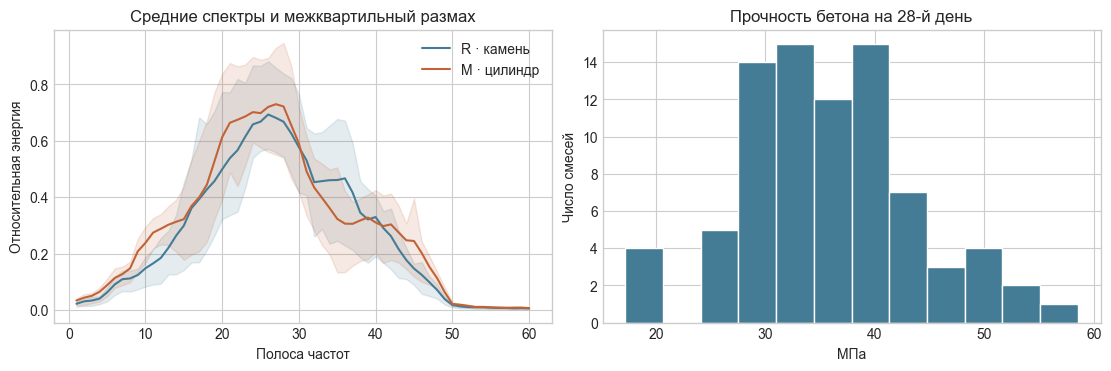

In [3]:
# Визуализируем только train. Слева спектры по классам, справа распределение прочности.
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6), layout="constrained")
x_train, _, y_train, _ = data["classification"]
for label, name, color in [(0, "R · камень", "#447c95"), (1, "M · цилиндр", "#c26337")]:
    group = x_train.loc[y_train == label]
    q1, q3 = group.quantile([0.25, 0.75]).to_numpy()
    axis = np.arange(1, len(bands) + 1)
    axes[0].plot(axis, group.mean(), label=name, color=color)
    axes[0].fill_between(axis, q1, q3, color=color, alpha=0.14)
axes[0].set(title="Средние спектры и межквартильный размах",
            xlabel="Полоса частот", ylabel="Относительная энергия")
axes[0].legend()
axes[1].hist(data["regression"][2], bins=12, color="#447c95", edgecolor="white")
axes[1].set(title="Прочность бетона на 28-й день", xlabel="МПа", ylabel="Число смесей")
plt.show()

## Гипотеза о новых признаках

График Sonar показывает средние профили и разброс по классам. Проверяем, помогают ли десять средних и стандартных отклонений по группам из шести соседних полос, а также девять разностей между средними соседних групп. Они описывают форму спектра на более грубой шкале. В регрессии проверяем массу вяжущего, водовяжущее отношение, доли золы, шлака и добавки, а также долю мелкого заполнителя. Эти отношения описывают рецептуру относительно её масштаба. Исходные признаки сохраняем.

In [4]:
# Общая схема эксперимента. Все трансформации входят в Pipeline.
def make_features(X, task):
    """Добавить признаки, вычисляемые отдельно для каждой строки."""
    X = np.asarray(X, dtype=float)
    if task == "classification":
        groups = X.reshape(len(X), 10, 6)
        means = groups.mean(axis=2)
        spread = groups.std(axis=2)
        return np.column_stack((X, means, spread, np.diff(means, axis=1)))

    cement, slag, ash, water, sp, coarse, fine = X.T
    binder = cement + slag + ash
    return np.column_stack((X, binder, water / binder, ash / binder,
                            slag / binder, sp / binder, fine / (fine + coarse)))


def make_pipeline(model, task, features=False, scale=False):
    feature_step = FunctionTransformer(make_features, kw_args={"task": task}) if features else "passthrough"
    return Pipeline([("features", feature_step),
                     ("scale", StandardScaler() if scale else "passthrough"),
                     ("model", model)])


protocols = {
    "classification": (StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED),
                       make_scorer(f1_score, average="macro")),
    "regression": (KFold(n_splits=5, shuffle=True, random_state=SEED),
                   "neg_mean_absolute_error"),
}
task_names = {"classification": "Классификация", "regression": "Регрессия"}
variants = ["sklearn · база", "sklearn · подбор", "Своя · база", "Своя · перенос"]
results = []
predictions = []

In [5]:
# Проверяем гипотезы на train, переносим выбранные настройки и оцениваем 4 версии.
def run_experiment(lab, task, base, own, grid, hypotheses):
    X_train, X_test, y_train, y_test = data[task]
    cv, scorer = protocols[task]
    direction = 1 if task == "classification" else -1
    baseline = make_pipeline(base, task)
    base_scores = cross_val_score(baseline, X_train, y_train, cv=cv, scoring=scorer)
    cv_rows = [{"Вариант": "Исходный бейзлайн", "Среднее CV": direction * base_scores.mean(),
                "SD по фолдам": base_scores.std(ddof=1)}]
    for title, options, params in hypotheses:
        candidate = make_pipeline(clone(base).set_params(**params), task, **options)
        scores = cross_val_score(candidate, X_train, y_train, cv=cv, scoring=scorer)
        cv_rows.append({"Вариант": title, "Среднее CV": direction * scores.mean(),
                        "SD по фолдам": scores.std(ddof=1)})

    # Сетка включает исходную настройку. При равенстве GridSearchCV берёт первую комбинацию.
    search = GridSearchCV(baseline, grid, cv=cv, scoring=scorer, error_score="raise")
    search.fit(X_train, y_train)
    best_scores = np.array([search.cv_results_[f"split{i}_test_score"][search.best_index_]
                            for i in range(cv.get_n_splits())])
    cv_rows.append({"Вариант": "Совместный поиск", "Среднее CV": direction * best_scores.mean(),
                    "SD по фолдам": best_scores.std(ddof=1)})
    display(Markdown(f"#### {task_names[task]}"))
    display(pd.DataFrame(cv_rows))
    options = {k: search.best_estimator_.named_steps[k] != "passthrough"
               for k in ("features", "scale")}
    params = {k.split("__", 1)[1]: v for k, v in search.best_params_.items()
              if k.startswith("model__")}
    n_candidates = len(search.cv_results_["params"])
    model_name = type(search.best_estimator_.named_steps["model"]).__name__
    display(Markdown(f"Проверено комбинаций — {n_candidates}. Модель — `{model_name}`. "
                     f"Выбранные настройки — `{options | params}`."))

    models = [baseline.fit(X_train, y_train), search.best_estimator_,
              make_pipeline(own(), task).fit(X_train, y_train),
              make_pipeline(own(**params), task, **options).fit(X_train, y_train)]
    lab_rows = []
    for variant, model, cv_score in zip(variants, models,
                                        [direction * base_scores.mean(), direction * best_scores.mean(),
                                         np.nan, np.nan]):
        y_pred = model.predict(X_test)
        assert len(y_pred) == len(y_test) and np.isfinite(y_pred).all()
        if task == "classification":
            metrics = {"F1_macro": f1_score(y_test, y_pred, average="macro"),
                       "Accuracy": accuracy_score(y_test, y_pred)}
        else:
            metrics = {"MAE": mean_absolute_error(y_test, y_pred),
                       "RMSE": root_mean_squared_error(y_test, y_pred),
                       "R2": r2_score(y_test, y_pred)}
        lab_rows.append({"lab": lab, "task": task, "variant": variant, "CV": cv_score, **metrics})
        predictions.extend({"lab": lab, "task": task, "variant": variant,
                            "row": int(index), "actual": float(actual), "predicted": float(pred)}
                           for index, actual, pred in zip(y_test.index, y_test, y_pred))
    table = pd.DataFrame(lab_rows).set_index("variant").drop(columns=["lab", "task"])
    display(table)
    results.extend(lab_rows)

    # В тексте показываем все обязательные сравнения по основной метрике.
    key = "F1_macro" if task == "classification" else "MAE"
    unit = "" if task == "classification" else " МПа"
    base_score, tuned, manual, manual_tuned = table[key]
    comparisons = [
        ("Подбор sklearn к исходной модели", tuned, base_score),
        ("Своя база к исходной sklearn", manual, base_score),
        ("Своя с переносом к улучшенной sklearn", manual_tuned, tuned),
        ("Своя с переносом к своей базе", manual_tuned, manual),
    ]
    lines = []
    for label, value, reference in comparisons:
        delta = value - reference
        effect = "без изменения" if abs(delta) < 1e-9 else ("лучше" if direction * delta > 0 else "хуже")
        lines.append(f"- {label} — {key} {value:.4f} против {reference:.4f}{unit}. "
                     f"Разница {delta:+.4f}{unit}, {effect} на этом тесте.")
    display(Markdown("\n".join(lines)))


def grid_for(task, model_grid, *, scale=False):
    """Собрать настройки Pipeline и модели. Первой идёт комбинация без преобразований."""
    return {"features": ["passthrough", FunctionTransformer(make_features, kw_args={"task": task})],
            "scale": ["passthrough", StandardScaler()] if scale else ["passthrough"],
            **{f"model__{key}": values for key, values in model_grid.items()}}

## Лабораторная работа 1 · Метод ближайших соседей

**Гипотезы.** Масштабирование может уменьшить влияние переменных с большими числовыми значениями. Новые признаки могут дать более полезное расстояние между наблюдениями. Проверяем также число соседей, веса и евклидову или манхэттенскую метрику.

### Собственная реализация

Собственная реализация хранит train, рассчитывает расстояния, сортирует соседей и усредняет их ответы. В классификации среднее кодов 0 и 1 превращается в голосование. При совпадении с обучающей точкой в режиме обратных расстояний голосуют только совпавшие точки.

In [6]:
# KNN с нуля. Для каждого объекта ищем ближайшие точки и агрегируем их ответы.
class OwnKNN(BaseEstimator):
    def __init__(self, classification, n_neighbors=5, weights="uniform", p=2):
        self.classification = classification
        self.n_neighbors = n_neighbors
        self.weights = weights
        self.p = p

    def fit(self, X, y):
        self.X_ = np.asarray(X, dtype=float)
        self.y_ = np.asarray(y, dtype=float)
        return self

    def predict(self, X):
        differences = np.abs(np.asarray(X, dtype=float)[:, None] - self.X_[None])
        if self.p == 1:
            distances = differences.sum(axis=2)
        else:
            distances = np.sqrt(np.square(differences).sum(axis=2))
        indices = np.argsort(distances, axis=1, kind="stable")[:, :self.n_neighbors]
        targets = self.y_[indices]
        if self.weights == "distance":
            nearest = np.take_along_axis(distances, indices, axis=1)
            zeros = nearest == 0
            weights = np.divide(1.0, nearest, out=np.zeros_like(nearest), where=~zeros)
            weights = np.where(zeros.any(axis=1, keepdims=True), zeros, weights)
            prediction = (weights * targets).sum(axis=1) / weights.sum(axis=1)
        else:
            prediction = targets.mean(axis=1)
        return (prediction > 0.5).astype(int) if self.classification else prediction

### Проверка гипотез и сравнение на тестовой выборке

Верхняя таблица для каждой задачи показывает среднее качество на пяти фолдах train, нижняя — результаты четырёх версий на отложенных данных. Строка «Совместный поиск» может сохранить исходную настройку, если она лучше проверенных вариантов.

In [7]:
# Проверяем стандартизацию, инженерные признаки и параметры соседства.
for task, base, classification in [
    ("classification", KNeighborsClassifier(), True),
    ("regression", KNeighborsRegressor(), False),
]:
    own = lambda **params: OwnKNN(classification, **params)
    grid = grid_for(task, {"n_neighbors": [5, 3, 9, 15], "weights": ["uniform", "distance"],
                           "p": [2, 1]}, scale=True)
    run_experiment(1, task, base, own, grid, [
        ("Только стандартизация", {"scale": True}, {}),
        ("Только новые признаки", {"features": True}, {}),
        ("Веса по расстоянию", {}, {"weights": "distance"}),
    ])

#### Классификация

,Вариант,Среднее CV,SD по фолдам
0,Исходный бейзлайн,0.7054,0.0483
1,Только стандартизация,0.7637,0.0569
2,Только новые признаки,0.7009,0.0553
3,Веса по расстоянию,0.7529,0.0659
4,Совместный поиск,0.8476,0.0473


Проверено комбинаций — 64. Модель — `KNeighborsClassifier`. Выбранные настройки — `{'features': True, 'scale': True, 'n_neighbors': 3, 'p': 1, 'weights': 'uniform'}`.

,CV,F1_macro,Accuracy
variant,,,
sklearn · база,0.7054,0.8325,0.8333
sklearn · подбор,0.8476,0.8803,0.8810
Своя · база,NaN,0.8325,0.8333
Своя · перенос,NaN,0.8803,0.8810


- Подбор sklearn к исходной модели — F1_macro 0.8803 против 0.8325. Разница +0.0479, лучше на этом тесте.
- Своя база к исходной sklearn — F1_macro 0.8325 против 0.8325. Разница +0.0000, без изменения на этом тесте.
- Своя с переносом к улучшенной sklearn — F1_macro 0.8803 против 0.8803. Разница +0.0000, без изменения на этом тесте.
- Своя с переносом к своей базе — F1_macro 0.8803 против 0.8325. Разница +0.0479, лучше на этом тесте.

#### Регрессия

,Вариант,Среднее CV,SD по фолдам
0,Исходный бейзлайн,4.2848,0.8965
1,Только стандартизация,3.8654,0.6571
2,Только новые признаки,3.5258,1.0648
3,Веса по расстоянию,3.3447,0.8342
4,Совместный поиск,2.4060,0.3678


Проверено комбинаций — 64. Модель — `KNeighborsRegressor`. Выбранные настройки — `{'features': True, 'scale': True, 'n_neighbors': 3, 'p': 2, 'weights': 'distance'}`.

,CV,MAE,RMSE,R2
variant,,,,
sklearn · база,4.2848,2.5214,2.9358,0.8297
sklearn · подбор,2.4060,2.1758,2.4733,0.8791
Своя · база,NaN,2.5214,2.9358,0.8297
Своя · перенос,NaN,2.1758,2.4733,0.8791


- Подбор sklearn к исходной модели — MAE 2.1758 против 2.5214 МПа. Разница -0.3456 МПа, лучше на этом тесте.
- Своя база к исходной sklearn — MAE 2.5214 против 2.5214 МПа. Разница +0.0000 МПа, без изменения на этом тесте.
- Своя с переносом к улучшенной sklearn — MAE 2.1758 против 2.1758 МПа. Разница +0.0000 МПа, без изменения на этом тесте.
- Своя с переносом к своей базе — MAE 2.1758 против 2.5214 МПа. Разница -0.3456 МПа, лучше на этом тесте.

### Вывод

Для Sonar одни дополнительные признаки не улучшили средний F1 на CV. В сочетании со стандартизацией, манхэттенским расстоянием и тремя соседями тестовый F1-macro вырос с 0,8325 до 0,8803. Для бетона перенос настройки снизил MAE собственной модели с 2,5214 до 2,1758 МПа.

## Лабораторная работа 2 · Логистическая и линейная регрессия

**Гипотезы.** Проверяем масштабирование, новые признаки и регуляризацию. Для классификации параметр C задаёт обратную силу L2-штрафа. Для прочности сравниваем обычный метод наименьших квадратов и Ridge с различными значениями штрафа.

### Собственная реализация

Логистическая модель минимизирует логистическую потерю методом Ньютона. Вычисляем градиент и матрицу вторых производных, решаем линейную систему для шага и уменьшаем шаг при необходимости. Линейная модель решает задачу наименьших квадратов через NumPy, а для Ridge добавляет к системе строки штрафа. В обеих моделях свободный член остаётся без штрафа.

In [8]:
# Логистическая и линейная регрессия. Свободный член не штрафуется.
class OwnLogistic(BaseEstimator):
    def __init__(self, C=1.0):
        self.C = C

    def fit(self, X, y):
        X = np.column_stack((np.ones(len(X)), np.asarray(X, dtype=float)))
        y = np.asarray(y, dtype=float)

        def objective(w):
            logits = X @ w
            return np.sum(np.logaddexp(0, logits) - y * logits) + np.sum(w[1:]**2) / (2 * self.C)

        # Градиент и гессиан логистической потери с L2-штрафом.
        w = np.zeros(X.shape[1])
        penalty = np.diag(np.r_[0.0, np.full(X.shape[1] - 1, 1 / self.C)])
        for _ in range(80):
            probability = expit(X @ w)
            gradient = X.T @ (probability - y) + penalty @ w
            if np.linalg.norm(gradient, ord=np.inf) < 1e-7:
                break
            curvature = probability * (1 - probability)
            hessian = X.T @ (curvature[:, None] * X) + penalty
            step = np.linalg.solve(hessian, gradient)

            # Уменьшаем шаг, пока функция потерь не убывает достаточно.
            rate = 1.0
            current_loss = objective(w)
            descent = 1e-4 * (gradient @ step)
            while objective(w - rate * step) > current_loss - rate * descent:
                rate *= 0.5
            w -= rate * step
        self.intercept_, self.coef_ = w[0], w[1:]
        return self

    def predict(self, X):
        return (np.asarray(X) @ self.coef_ + self.intercept_ > 0).astype(int)


class OwnLinear(BaseEstimator):
    def __init__(self, alpha=0.0):
        self.alpha = alpha

    def fit(self, X, y):
        design = np.column_stack((np.ones(len(X)), np.asarray(X, dtype=float)))
        targets = np.asarray(y, dtype=float)
        if self.alpha:
            penalty = np.sqrt(self.alpha) * np.eye(design.shape[1])[1:]
            design = np.vstack((design, penalty))
            targets = np.r_[targets, np.zeros(len(penalty))]
        self.intercept_, *weights = np.linalg.lstsq(design, targets, rcond=None)[0]
        self.coef_ = np.asarray(weights)
        return self

    def predict(self, X):
        return np.asarray(X) @ self.coef_ + self.intercept_

### Проверка гипотез и сравнение на тестовой выборке

Верхняя таблица для каждой задачи показывает среднее качество на пяти фолдах train, нижняя — результаты четырёх версий на отложенных данных. Строка «Совместный поиск» может сохранить исходную настройку, если она лучше проверенных вариантов.

In [9]:
# Подбираем силу регуляризации логистической модели и сравниваем OLS с Ridge.
logistic = LogisticRegression(max_iter=3000, tol=1e-8)
run_experiment(2, "classification", logistic, OwnLogistic,
               grid_for("classification", {"C": [1.0, 0.03, 0.1, 10.0, 50.0]}, scale=True), [
    ("Только стандартизация", {"scale": True}, {}),
    ("Только новые признаки", {"features": True}, {}),
    ("Более сильная регуляризация", {}, {"C": 0.1}),
])

linear = LinearRegression()
linear_grid = grid_for("regression", {}, scale=True)
ridge_grid = {**grid_for("regression", {"alpha": [0.01, 0.1, 1.0, 10.0]}, scale=True),
              "model": [Ridge(solver="svd")]}
run_experiment(2, "regression", linear, OwnLinear, [linear_grid, ridge_grid], [
    ("Только стандартизация", {"scale": True}, {}),
    ("Только новые признаки", {"features": True}, {}),
    ("Стандартизация и новые признаки", {"scale": True, "features": True}, {}),
])

#### Классификация

,Вариант,Среднее CV,SD по фолдам
0,Исходный бейзлайн,0.7590,0.0446
1,Только стандартизация,0.7855,0.0498
2,Только новые признаки,0.7778,0.0635
3,Более сильная регуляризация,0.6440,0.0759
4,Совместный поиск,0.8291,0.0352


Проверено комбинаций — 20. Модель — `LogisticRegression`. Выбранные настройки — `{'features': True, 'scale': True, 'C': 1.0}`.

,CV,F1_macro,Accuracy
variant,,,
sklearn · база,0.7590,0.8078,0.8095
sklearn · подбор,0.8291,0.8568,0.8571
Своя · база,NaN,0.8078,0.8095
Своя · перенос,NaN,0.8568,0.8571


- Подбор sklearn к исходной модели — F1_macro 0.8568 против 0.8078. Разница +0.0490, лучше на этом тесте.
- Своя база к исходной sklearn — F1_macro 0.8078 против 0.8078. Разница +0.0000, без изменения на этом тесте.
- Своя с переносом к улучшенной sklearn — F1_macro 0.8568 против 0.8568. Разница +0.0000, без изменения на этом тесте.
- Своя с переносом к своей базе — F1_macro 0.8568 против 0.8078. Разница +0.0490, лучше на этом тесте.

#### Регрессия

,Вариант,Среднее CV,SD по фолдам
0,Исходный бейзлайн,2.2884,0.3956
1,Только стандартизация,2.2884,0.3956
2,Только новые признаки,2.3196,0.5578
3,Стандартизация и новые признаки,2.3196,0.5578
4,Совместный поиск,2.2852,0.3866


Проверено комбинаций — 20. Модель — `Ridge`. Выбранные настройки — `{'features': False, 'scale': True, 'alpha': 0.1}`.

,CV,MAE,RMSE,R2
variant,,,,
sklearn · база,2.2884,1.7310,2.0685,0.9154
sklearn · подбор,2.2852,1.7301,2.0653,0.9157
Своя · база,NaN,1.7310,2.0685,0.9154
Своя · перенос,NaN,1.7301,2.0653,0.9157


- Подбор sklearn к исходной модели — MAE 1.7301 против 1.7310 МПа. Разница -0.0009 МПа, лучше на этом тесте.
- Своя база к исходной sklearn — MAE 1.7310 против 1.7310 МПа. Разница -0.0000 МПа, без изменения на этом тесте.
- Своя с переносом к улучшенной sklearn — MAE 1.7301 против 1.7301 МПа. Разница +0.0000 МПа, без изменения на этом тесте.
- Своя с переносом к своей базе — MAE 1.7301 против 1.7310 МПа. Разница -0.0009 МПа, лучше на этом тесте.

### Вывод

Для классификации сработало сочетание новых признаков и стандартизации. В регрессии Ridge со стандартизацией снизила тестовую MAE с 1,7310 до 1,7301 МПа. На этой выборке разница между линейными моделями мала.

## Лабораторная работа 3 · Решающее дерево

**Гипотезы.** Ограничение глубины и увеличение минимального листа могут уменьшить переобучение. Новые признаки могут дать пороги, которые трудно выразить одним разбиением по исходной колонке.

### Собственная реализация

CART перебирает пороги между различными соседними значениями. В классификации выбирается максимальное уменьшение взвешенной нечистоты Джини. В регрессии выбирается максимальное уменьшение суммы квадратов ошибок. Лист предсказывает наиболее частый класс или среднее значение.

In [10]:
# CART с нуля. Узел хранит среднее или бинарную вероятность класса M.
class TreeNode:
    def __init__(self, value):
        self.value = float(value)
        self.feature = self.threshold = None
        self.left = self.right = None


class OwnTree(BaseEstimator):
    def __init__(self, classification, max_depth=None, min_samples_leaf=1,
                 max_features=None, random_state=42):
        self.classification = classification
        self.max_depth = max_depth
        self.min_samples_leaf = min_samples_leaf
        self.max_features = max_features
        self.random_state = random_state

    def fit(self, X, y):
        self.rng_ = np.random.default_rng(self.random_state)
        self.root_ = self._grow(np.asarray(X, dtype=float), np.asarray(y, dtype=float), 0)
        return self

    def _grow(self, X, y, depth):
        node = TreeNode(y.mean())
        n, n_features = X.shape
        leaf = self.min_samples_leaf
        if (n < 2 * leaf or np.ptp(y) == 0
                or self.max_depth is not None and depth >= self.max_depth):
            return node

        # Для числового признака проверяем пороги между соседними значениями.
        # Суммы слева и справа получаем из накопительных сумм за один проход.
        if self.max_features == "sqrt":
            budget = max(1, int(np.sqrt(n_features)))
        elif isinstance(self.max_features, float):
            budget = max(1, int(self.max_features * n_features))
        else:
            budget = n_features
        features = self.rng_.permutation(n_features)
        total = y.sum()
        candidates = np.arange(leaf, n - leaf + 1)
        best_gain = 0.0
        for position, feature in enumerate(features):
            if position >= budget and node.feature is not None:
                break
            order = np.argsort(X[:, feature], kind="stable")
            values = X[order, feature]
            split = candidates[values[candidates - 1] < values[candidates]]
            if not split.size:
                continue
            left_sum = np.cumsum(y[order])[split - 1]
            right_sum = total - left_sum
            # Эта величина пропорциональна снижению Gini (двоичный y)
            # либо снижению суммы квадратов ошибок (вещественный y).
            gains = (left_sum**2 / split + right_sum**2 / (n - split) - total**2 / n)
            winner = int(np.argmax(gains))
            if gains[winner] > best_gain + 1e-12:
                boundary = split[winner]
                best_gain = gains[winner]
                node.feature = feature
                node.threshold = (values[boundary - 1] + values[boundary]) / 2

        if node.feature is not None:
            left = X[:, node.feature] <= node.threshold
            node.left = self._grow(X[left], y[left], depth + 1)
            node.right = self._grow(X[~left], y[~left], depth + 1)
        return node

    def leaves(self, X):
        output = []
        for row in np.asarray(X, dtype=float):
            node = self.root_
            while node.feature is not None:
                node = node.left if row[node.feature] <= node.threshold else node.right
            output.append(node)
        return output

    def predict_value(self, X):
        return np.array([node.value for node in self.leaves(X)])

    def predict(self, X):
        values = self.predict_value(X)
        return (values > 0.5).astype(int) if self.classification else values

### Проверка гипотез и сравнение на тестовой выборке

Верхняя таблица для каждой задачи показывает среднее качество на пяти фолдах train, нижняя — результаты четырёх версий на отложенных данных. Строка «Совместный поиск» может сохранить исходную настройку, если она лучше проверенных вариантов.

In [11]:
# Проверяем ограничение глубины и размера листа на решающем дереве.
for task, base, classification in [
    ("classification", DecisionTreeClassifier(random_state=SEED), True),
    ("regression", DecisionTreeRegressor(random_state=SEED), False),
]:
    own = lambda **params: OwnTree(classification, random_state=SEED, **params)
    grid = grid_for(task, {"max_depth": [None, 2, 4, 7], "min_samples_leaf": [1, 3, 6]})
    run_experiment(3, task, base, own, grid, [
        ("Только новые признаки", {"features": True}, {}),
        ("Ограничение глубины до 4", {}, {"max_depth": 4}),
        ("Минимум 3 объекта в листе", {}, {"min_samples_leaf": 3}),
    ])

#### Классификация

,Вариант,Среднее CV,SD по фолдам
0,Исходный бейзлайн,0.7249,0.1295
1,Только новые признаки,0.7314,0.1095
2,Ограничение глубины до 4,0.7209,0.1414
3,Минимум 3 объекта в листе,0.7424,0.1009
4,Совместный поиск,0.7496,0.1014


Проверено комбинаций — 24. Модель — `DecisionTreeClassifier`. Выбранные настройки — `{'features': True, 'scale': False, 'max_depth': None, 'min_samples_leaf': 3}`.

,CV,F1_macro,Accuracy
variant,,,
sklearn · база,0.7249,0.8286,0.8333
sklearn · подбор,0.7496,0.7379,0.7381
Своя · база,NaN,0.7856,0.7857
Своя · перенос,NaN,0.8095,0.8095


- Подбор sklearn к исходной модели — F1_macro 0.7379 против 0.8286. Разница -0.0906, хуже на этом тесте.
- Своя база к исходной sklearn — F1_macro 0.7856 против 0.8286. Разница -0.0430, хуже на этом тесте.
- Своя с переносом к улучшенной sklearn — F1_macro 0.8095 против 0.7379. Разница +0.0716, лучше на этом тесте.
- Своя с переносом к своей базе — F1_macro 0.8095 против 0.7856. Разница +0.0239, лучше на этом тесте.

#### Регрессия

,Вариант,Среднее CV,SD по фолдам
0,Исходный бейзлайн,3.9039,0.8850
1,Только новые признаки,2.7166,1.5030
2,Ограничение глубины до 4,3.7314,0.8436
3,Минимум 3 объекта в листе,3.9686,0.8450
4,Совместный поиск,2.4999,0.4796


Проверено комбинаций — 24. Модель — `DecisionTreeRegressor`. Выбранные настройки — `{'features': True, 'scale': False, 'max_depth': 4, 'min_samples_leaf': 1}`.

,CV,MAE,RMSE,R2
variant,,,,
sklearn · база,3.9039,2.9905,4.2153,0.6488
sklearn · подбор,2.4999,2.9547,3.4316,0.7673
Своя · база,NaN,3.5567,4.5507,0.5907
Своя · перенос,NaN,2.9380,3.4530,0.7644


- Подбор sklearn к исходной модели — MAE 2.9547 против 2.9905 МПа. Разница -0.0358 МПа, лучше на этом тесте.
- Своя база к исходной sklearn — MAE 3.5567 против 2.9905 МПа. Разница +0.5662 МПа, хуже на этом тесте.
- Своя с переносом к улучшенной sklearn — MAE 2.9380 против 2.9547 МПа. Разница -0.0166 МПа, лучше на этом тесте.
- Своя с переносом к своей базе — MAE 2.9380 против 3.5567 МПа. Разница -0.6186 МПа, лучше на этом тесте.

### Вывод

У дерева sklearn средний F1-macro по CV вырос с 0,7249 до 0,7496, а тестовый F1-macro снизился с 0,8286 до 0,7379. Для своей модели перенос настройки улучшил тестовый F1 и снизил ошибку регрессии.

## Лабораторная работа 4 · Случайный лес

**Гипотезы.** Меняем число деревьев, размер листа, глубину и долю признаков для каждого узла. Случайный выбор признаков повышает разнообразие деревьев, но слишком маленькое подмножество может исключить полезные признаки.

### Собственная реализация

Каждое собственное дерево обучается на bootstrap-выборке. В узле рассматривается случайное подмножество признаков. Для классификации усредняем вероятности класса из листьев, для регрессии — ответы деревьев. Генераторы случайных чисел, обработка одинаковых порогов и учёт bootstrap-повторов при ограничении размера листа могут дать отличие от sklearn.

In [12]:
# Случайный лес с нуля. Деревья обучаются на независимых bootstrap-выборках.
class OwnForest(BaseEstimator):
    def __init__(self, classification, n_estimators=100, max_depth=None,
                 min_samples_leaf=1, max_features=None, random_state=42):
        self.classification = classification
        self.n_estimators = n_estimators
        self.max_depth = max_depth
        self.min_samples_leaf = min_samples_leaf
        self.max_features = max_features
        self.random_state = random_state

    def fit(self, X, y):
        X, y = np.asarray(X, dtype=float), np.asarray(y, dtype=float)
        rng = np.random.default_rng(self.random_state)
        self.trees_ = []
        for _ in range(self.n_estimators):
            sample = rng.integers(len(X), size=len(X))
            tree = OwnTree(self.classification, max_depth=self.max_depth,
                           min_samples_leaf=self.min_samples_leaf, max_features=self.max_features,
                           random_state=int(rng.integers(2**31 - 1)))
            self.trees_.append(tree.fit(X[sample], y[sample]))
        return self

    def predict(self, X):
        values = np.mean([tree.predict_value(X) for tree in self.trees_], axis=0)
        return (values > 0.5).astype(int) if self.classification else values

### Проверка гипотез и сравнение на тестовой выборке

Верхняя таблица для каждой задачи показывает среднее качество на пяти фолдах train, нижняя — результаты четырёх версий на отложенных данных. Строка «Совместный поиск» может сохранить исходную настройку, если она лучше проверенных вариантов.

In [13]:
# Проверяем влияние размера леса и числа признаков на каждом разбиении.
for task, base, classification, default_features in [
    ("classification", RandomForestClassifier(random_state=SEED), True, "sqrt"),
    ("regression", RandomForestRegressor(random_state=SEED), False, 1.0),
]:
    own = lambda **params: OwnForest(
        classification, random_state=SEED, **({"max_features": default_features} | params))
    grid = grid_for(task, {"n_estimators": [100, 50], "max_depth": [None, 5],
                           "min_samples_leaf": [1, 3],
                           "max_features": [default_features, 0.5]})
    run_experiment(4, task, base, own, grid, [
        ("Только новые признаки", {"features": True}, {}),
        ("Доля признаков 0.5", {}, {"max_features": 0.5}),
        ("Минимум 3 объекта в листе", {}, {"min_samples_leaf": 3}),
    ])

#### Классификация

,Вариант,Среднее CV,SD по фолдам
0,Исходный бейзлайн,0.7600,0.0697
1,Только новые признаки,0.7707,0.0930
2,Доля признаков 0.5,0.7670,0.0825
3,Минимум 3 объекта в листе,0.7798,0.0809
4,Совместный поиск,0.7990,0.0641


Проверено комбинаций — 32. Модель — `RandomForestClassifier`. Выбранные настройки — `{'features': False, 'scale': False, 'max_depth': 5, 'max_features': 'sqrt', 'min_samples_leaf': 1, 'n_estimators': 50}`.

,CV,F1_macro,Accuracy
variant,,,
sklearn · база,0.7600,0.8078,0.8095
sklearn · подбор,0.7990,0.8558,0.8571
Своя · база,NaN,0.8056,0.8095
Своя · перенос,NaN,0.8091,0.8095


- Подбор sklearn к исходной модели — F1_macro 0.8558 против 0.8078. Разница +0.0481, лучше на этом тесте.
- Своя база к исходной sklearn — F1_macro 0.8056 против 0.8078. Разница -0.0022, хуже на этом тесте.
- Своя с переносом к улучшенной sklearn — F1_macro 0.8091 против 0.8558. Разница -0.0467, хуже на этом тесте.
- Своя с переносом к своей базе — F1_macro 0.8091 против 0.8056. Разница +0.0035, лучше на этом тесте.

#### Регрессия

,Вариант,Среднее CV,SD по фолдам
0,Исходный бейзлайн,3.0265,0.7036
1,Только новые признаки,2.4885,0.3650
2,Доля признаков 0.5,3.4385,0.9054
3,Минимум 3 объекта в листе,3.2240,0.6548
4,Совместный поиск,2.3676,0.6587


Проверено комбинаций — 32. Модель — `RandomForestRegressor`. Выбранные настройки — `{'features': True, 'scale': False, 'max_depth': None, 'max_features': 0.5, 'min_samples_leaf': 1, 'n_estimators': 100}`.

,CV,MAE,RMSE,R2
variant,,,,
sklearn · база,3.0265,2.5684,3.2853,0.7867
sklearn · подбор,2.3676,1.9889,2.4086,0.8853
Своя · база,NaN,2.3209,2.8171,0.8431
Своя · перенос,NaN,2.0377,2.3542,0.8905


- Подбор sklearn к исходной модели — MAE 1.9889 против 2.5684 МПа. Разница -0.5795 МПа, лучше на этом тесте.
- Своя база к исходной sklearn — MAE 2.3209 против 2.5684 МПа. Разница -0.2474 МПа, лучше на этом тесте.
- Своя с переносом к улучшенной sklearn — MAE 2.0377 против 1.9889 МПа. Разница +0.0488 МПа, хуже на этом тесте.
- Своя с переносом к своей базе — MAE 2.0377 против 2.3209 МПа. Разница -0.2833 МПа, лучше на этом тесте.

### Вывод

Регрессионный лес выиграл от подбора в обеих реализациях. MAE уменьшилась с 2,5684 до 1,9889 МПа у sklearn и с 2,3209 до 2,0377 МПа у собственной модели. У классификационного леса собственная модель показала меньший прирост.

## Лабораторная работа 5 · Градиентный бустинг

**Гипотезы.** Сравниваем новые признаки, глубину слабых деревьев, темп обучения, число итераций и минимальный лист. Малый темп даёт меньший вклад каждого дерева, поэтому его эффект зависит от числа итераций.

### Собственная реализация

Стартовый прогноз равен среднему y для квадратичной потери либо логарифму отношения шансов для логистической. Каждое дерево учится на текущих остатках или антиградиенте. Для логистической потери в каждом листе выполняется поправка Ньютона. Прогноз обновляется с учётом темпа обучения.

In [14]:
# Градиентный бустинг с нуля. На каждом шаге обучаем дерево на антиградиенте.
class OwnBoost(BaseEstimator):
    def __init__(self, classification, n_estimators=100, learning_rate=0.1,
                 max_depth=3, min_samples_leaf=1, random_state=42):
        self.classification = classification
        self.n_estimators = n_estimators
        self.learning_rate = learning_rate
        self.max_depth = max_depth
        self.min_samples_leaf = min_samples_leaf
        self.random_state = random_state

    def fit(self, X, y):
        X, y = np.asarray(X, dtype=float), np.asarray(y, dtype=float)
        rng = np.random.default_rng(self.random_state)
        self.initial_ = float(logit(np.clip(y.mean(), 1e-12, 1 - 1e-12))
                              if self.classification else y.mean())
        raw = np.full(len(X), self.initial_)
        self.trees_ = []
        for _ in range(self.n_estimators):
            fitted = expit(raw) if self.classification else raw
            residual = y - fitted
            tree = OwnTree(False, max_depth=self.max_depth,
                           min_samples_leaf=self.min_samples_leaf,
                           random_state=int(rng.integers(2**31 - 1))).fit(X, residual)
            if self.classification:
                # Шаг Ньютона для логистической потери в каждом листе.
                groups = {}
                for i, node in enumerate(tree.leaves(X)):
                    groups.setdefault(node, []).append(i)
                for node, rows in groups.items():
                    hessian = np.sum(fitted[rows] * (1 - fitted[rows]))
                    node.value = float(residual[rows].sum() / max(hessian, 1e-12))
            raw += self.learning_rate * tree.predict_value(X)
            self.trees_.append(tree)
        return self

    def predict(self, X):
        raw = self.initial_ + self.learning_rate * np.sum(
            [tree.predict_value(X) for tree in self.trees_], axis=0)
        return (raw > 0).astype(int) if self.classification else raw

### Проверка гипотез и сравнение на тестовой выборке

Верхняя таблица для каждой задачи показывает среднее качество на пяти фолдах train, нижняя — результаты четырёх версий на отложенных данных. Строка «Совместный поиск» может сохранить исходную настройку, если она лучше проверенных вариантов.

In [15]:
# Подбираем глубину слабых деревьев, темп обучения и количество шагов.
for task, base, classification in [
    ("classification", GradientBoostingClassifier(random_state=SEED), True),
    ("regression", GradientBoostingRegressor(random_state=SEED), False),
]:
    own = lambda **params: OwnBoost(classification, random_state=SEED, **params)
    grid = grid_for(task, {"n_estimators": [100, 60], "learning_rate": [0.1, 0.04],
                           "max_depth": [3, 1, 2], "min_samples_leaf": [1, 3]})
    run_experiment(5, task, base, own, grid, [
        ("Только новые признаки", {"features": True}, {}),
        ("Глубина слабого дерева 1", {}, {"max_depth": 1}),
        ("Темп обучения 0.04", {}, {"learning_rate": 0.04}),
    ])

#### Классификация

,Вариант,Среднее CV,SD по фолдам
0,Исходный бейзлайн,0.7772,0.0277
1,Только новые признаки,0.7655,0.0969
2,Глубина слабого дерева 1,0.7783,0.0712
3,Темп обучения 0.04,0.7640,0.0389
4,Совместный поиск,0.8407,0.0581


Проверено комбинаций — 48. Модель — `GradientBoostingClassifier`. Выбранные настройки — `{'features': False, 'scale': False, 'learning_rate': 0.1, 'max_depth': 2, 'min_samples_leaf': 3, 'n_estimators': 60}`.

,CV,F1_macro,Accuracy
variant,,,
sklearn · база,0.7772,0.8568,0.8571
sklearn · подбор,0.8407,0.8568,0.8571
Своя · база,NaN,0.8568,0.8571
Своя · перенос,NaN,0.8568,0.8571


- Подбор sklearn к исходной модели — F1_macro 0.8568 против 0.8568. Разница +0.0000, без изменения на этом тесте.
- Своя база к исходной sklearn — F1_macro 0.8568 против 0.8568. Разница +0.0000, без изменения на этом тесте.
- Своя с переносом к улучшенной sklearn — F1_macro 0.8568 против 0.8568. Разница +0.0000, без изменения на этом тесте.
- Своя с переносом к своей базе — F1_macro 0.8568 против 0.8568. Разница +0.0000, без изменения на этом тесте.

#### Регрессия

,Вариант,Среднее CV,SD по фолдам
0,Исходный бейзлайн,2.2565,0.7000
1,Только новые признаки,1.8605,0.3931
2,Глубина слабого дерева 1,2.8150,0.7263
3,Темп обучения 0.04,2.4363,0.6343
4,Совместный поиск,1.6973,0.2916


Проверено комбинаций — 48. Модель — `GradientBoostingRegressor`. Выбранные настройки — `{'features': True, 'scale': False, 'learning_rate': 0.1, 'max_depth': 3, 'min_samples_leaf': 3, 'n_estimators': 100}`.

,CV,MAE,RMSE,R2
variant,,,,
sklearn · база,2.2565,2.2842,2.9035,0.8334
sklearn · подбор,1.6973,1.6226,1.9871,0.9220
Своя · база,NaN,2.3294,2.9594,0.8269
Своя · перенос,NaN,1.6349,2.0017,0.9208


- Подбор sklearn к исходной модели — MAE 1.6226 против 2.2842 МПа. Разница -0.6615 МПа, лучше на этом тесте.
- Своя база к исходной sklearn — MAE 2.3294 против 2.2842 МПа. Разница +0.0452 МПа, хуже на этом тесте.
- Своя с переносом к улучшенной sklearn — MAE 1.6349 против 1.6226 МПа. Разница +0.0123 МПа, хуже на этом тесте.
- Своя с переносом к своей базе — MAE 1.6349 против 2.3294 МПа. Разница -0.6944 МПа, лучше на этом тесте.

### Вывод

Для бетона добавление признаков рецептуры уже само по себе снизило MAE на CV с 2,2565 до 1,8605 МПа. Совместный подбор дал тестовую MAE 1,6226 МПа у sklearn и 1,6349 МПа у собственной версии. На Sonar F1-macro на тесте остался 0,8568 у всех четырёх версий.

## Сохранение результатов

CSV с метриками и предсказаниями читает итоговый ноутбук. Номер строки — нулевой индекс исходного файла данных без заголовка.

In [16]:
# Сохраняем метрики и предсказания, чтобы итоговый ноутбук работал независимо.
output_dir = Path("results")
output_dir.mkdir(exist_ok=True)
metrics_table = pd.DataFrame(results)
prediction_table = pd.DataFrame(predictions)
assert len(metrics_table) == 5 * 2 * 4
assert not metrics_table.duplicated(["lab", "task", "variant"]).any()
assert len(prediction_table) == 5 * 4 * sum(len(parts[1]) for parts in data.values())
metrics_table.to_csv(output_dir / "metrics.csv", index=False)
prediction_table.to_csv(output_dir / "predictions.csv", index=False)
print(f"Сохранено {len(metrics_table)} строк метрик и {len(prediction_table)} предсказаний.")

Сохранено 40 строк метрик и 1260 предсказаний.
